# Immune-Cell Gene Regulatory Networks in Early Breast Cancer Dissemination

Author:     Oona Kintscher \
Created:    17.10.2026

### Global Variables

In [68]:
REGION = "T"            
CELL_TYPE = "Activated T cells"

SEED = 42

### Import Required Libraries

In [69]:
import sys
sys.path.append("..")

import os, glob, pickle
import pandas as pd
import seaborn as sns
import numpy as np
import seaborn as sns
import scanpy as sc
import networkx as nx
import gseapy as gp
import matplotlib.pyplot as plt
import config.plotting as plot

from itertools import combinations
from scipy import sparse
from pathlib import Path
from dask.distributed import LocalCluster, Client
from arboreto.algo import grnboost2
from arboreto.utils import load_tf_names

from config.plotting import (
    MAIN_COLOR,
    ACCENT_COLOR,
    COLOR_PALETTE,
    COLOR_PALETTE_2,
    NAVY_WHITE
)

os.environ["REGION"] = REGION
os.environ["CELL_TYPE"] = CELL_TYPE
os.environ["RUN_GRN_INFERENCE"] = "1"
  
from config.settings import (
    HS_TFS_FNAME,
    DATABASES_GLOB,
    MOTIF_ANNOTATIONS_FNAME,
    SC_EXP_CLUSTERED_FNAME_LEGACY,
    REGION_DIR,
    MODULES_FNAME,
    MOTIFS_FNAME,
    REGULONS_FNAME,
    AUCELL_FNAME,
    SUBNETWORK_FOLDER
)

from ctxcore.rnkdb import FeatherRankingDatabase as RankingDatabase
from pyscenic.utils import modules_from_adjacencies
from pyscenic.prune import prune2df
from pyscenic.transform import df2regulons
from pyscenic.aucell import aucell

# Starting Workflow
---

## 1. Loading Preprocessed Adata Object 

In [70]:
adata = sc.read_h5ad(SC_EXP_CLUSTERED_FNAME_LEGACY)
print(adata)

print(
    f"Initial dimensions: {adata.n_obs:,} cells x "
    f"{adata.n_vars:,} genes"
)

AnnData object with n_obs × n_vars = 13140 × 27792
    obs: 'sample', 'patient', 'region', 'age', 'sex', 'tumor_size', 'lymph_nodes', 'cancer_type', 'grade', 'ER', 'PR', 'HER2', 'Ki67', 'stage', 'treatment', 'tumor_volume', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'size_factors', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.60', 'leiden_res_0.70', 'leiden_res_0.80', 'leiden_res_0.90', 'leiden_res_1.00', 'leiden_res_1.10', 'leiden_res_1.20', 'leiden_r0.20_s0', 'leiden_r0.20_s1', 'leiden_r0.20_s2', 'leiden_r0.20_s3', 'leiden_r0.20_s4', 'leiden_r0.20_s10', 'leiden_r0.20_s21', 'leiden_r0.20_s42', 'leiden_r0.20_s123', 'leiden_r0.20_s2026',

In [71]:
adata_cell_type = adata[
    (adata.obs["cell_type"] == CELL_TYPE)
].copy()

### Additional Gene Filtering

In [72]:
MIN_COUNTS_THRESHOLD = 10
MIN_VARIANCE_THRESHOLD = 0.1
MIN_BARCODES_THRESHOLD = 10

In [ ]:
n_before = adata.n_vars
adata_cell_type_filtered = adata_cell_type.copy()

# remove genes with very low expression across barcodes
X_counts = adata_cell_type_filtered.layers["counts"]
total_counts = np.asarray(X_counts.sum(axis=0)).ravel()
keep_counts = total_counts >= MIN_COUNTS_THRESHOLD

adata_cell_type_filtered = adata_cell_type_filtered[:, keep_counts].copy()
n_after_counts = adata_cell_type_filtered.n_vars

# remove zero-variance genes
X = adata_cell_type_filtered.X
mean = np.asarray(X.mean(axis=0)).ravel()
mean_sq = np.asarray(X.power(2).mean(axis=0)).ravel()
gene_var = np.maximum(mean_sq - mean**2, 0)

keep_variance = gene_var > MIN_VARIANCE_THRESHOLD

adata_cell_type_filtered = adata_cell_type_filtered[:, keep_variance].copy()
n_after_variance = adata_cell_type_filtered.n_vars

# remove genes expressed in too few barcodes
X = adata_cell_type_filtered.X
detected = np.asarray((X > 0).sum(axis=0)).ravel()
keep_barcodes = detected >= MIN_BARCODES_THRESHOLD

adata_cell_type_filtered = adata_cell_type_filtered[:, keep_barcodes].copy()
n_after_barcodes = adata_cell_type_filtered.n_vars

In [74]:
print(f"Initial genes: {n_before}")
print(f"Removed count filter: {n_before - n_after_counts}")
print(f"Removed variance filter: {n_after_counts - n_after_variance}")
print(f"Removed barcode filter: {n_after_variance - n_after_barcodes}")
print(f"Total genes removed: {n_before - n_after_barcodes}")

Initial genes: 27792
Removed count filter: 19678
Removed variance filter: 3355
Removed barcode filter: 15
Total genes removed: 23048


## 2. Extracting Subsets

In [75]:
adata_region = adata_cell_type_filtered[
    (adata_cell_type_filtered.obs["region"] == REGION)
].copy()

print(
    f"{REGION} Region - {adata_region.n_obs} cells x "
    f"{adata_region.n_vars} genes"
)

T Region - 96 cells x 4744 genes


In [76]:
X = adata_region.X

print("Shape:", X.shape)
print("Data type:", X.dtype)
print("Sparse matrix:", sparse.issparse(X))

values = X.data  
cell_sums = np.asarray(X.sum(axis=1)).ravel()

print("Minimum nonzero value:", values.min())
print("Maximum value:", values.max())
print("Mean nonzero value:", values.mean())
print("Fraction of integer-like values:",
      np.mean(np.isclose(values, np.round(values))))

Shape: (96, 4744)
Data type: float32
Sparse matrix: True
Minimum nonzero value: 0.23872471
Maximum value: 7.22801
Mean nonzero value: 1.2507519
Fraction of integer-like values: 1.1105681666740704e-05


### Extracting Raw Counts

In [77]:
X = adata_region.X.toarray()

expression_data = pd.DataFrame(
    X,
    columns=adata_region.var_names,
    index=adata_region.obs_names
)

### Derive List of Transcription Factors

In [78]:
tf_names = load_tf_names(HS_TFS_FNAME)
tf_names_present = sorted(set(tf_names).intersection(expression_data.columns))

### Input Data Summary 

In [79]:
print("Cells:", expression_data.shape[0])
print("Genes:", expression_data.shape[1])

print("TFs supplied:", len(tf_names))
print("TFs present:", len(tf_names_present))

display(expression_data.head())

Cells: 96
Genes: 4744
TFs supplied: 1839
TFs present: 424


gene_symbol,NOC2L,HES4,ISG15,SDF4,UBE2J2,INTS11,AURKAIP1,CCNL2,MRPL20,SSU72,...,MT-CO2,MT-ATP8,MT-ATP6,MT-CO3,MT-ND3,MT-ND4L,MT-ND4,MT-ND5,MT-ND6,MT-CYB
barcode,,,,,,,,,,,,,,,,,,,,,
ACCGTTCCACAGTGTT-T2,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,1.640550,0.000000,...,3.534096,1.640550,4.272296,4.328680,4.432721,1.640550,4.480945,2.600763,0.000000,3.648631
TGTTCCGCAAGTGGAC-T2,0.0,1.801154,0.698795,0.000000,0.0,0.0,0.698795,0.000000,0.698795,0.000000,...,4.036415,0.698795,4.543742,4.328602,4.245207,1.801154,3.981344,3.055252,0.000000,3.902855
CAATACGAGAGCAAGA-T2,0.0,0.000000,0.000000,1.091004,0.0,0.0,0.687446,0.687446,1.091004,0.687446,...,4.193430,0.687446,4.395425,3.940031,3.544242,1.377731,3.702418,3.390146,0.687446,3.652422
CACCAAAAGGTTCTAC-T2,0.0,0.000000,1.339647,0.000000,0.0,0.0,0.000000,0.662292,1.339647,1.057257,...,3.745406,0.000000,4.186726,3.700011,3.405063,2.141695,3.927488,2.649661,0.000000,3.549972
GCCAACGAGCTTGTGT-T2,0.0,0.000000,0.569743,0.569743,0.0,0.0,0.930441,0.569743,0.569743,0.569743,...,4.574471,0.930441,4.420719,4.383086,3.692834,0.569743,3.867791,2.696021,1.576722,3.867791


# PHASE I - GRN Inference (GRNBoost2)
---

### Infer GRN Network using grnboost2()

In [80]:
N_WORKERS = min(8, os.cpu_count() or 1)

cluster = LocalCluster(
    n_workers=N_WORKERS,
    threads_per_worker=1,
    dashboard_address=None
)

client = Client(cluster)

try:
    network = grnboost2(
        expression_data=expression_data,
        tf_names=tf_names_present,
        client_or_address=client,
        seed=SEED,
        verbose=True
    )
finally:
    client.close()
    cluster.close()

preparing dask client
parsing input
creating dask graph
8 partitions
computing dask graph
not shutting down client, client was created externally
finished


In [81]:
network_df = pd.DataFrame(network)

network_df.to_csv(
    REGION_DIR / "network.csv",
    sep="\t",
    index=False
)

## GRN Overview

In [82]:
print("\nColumn Indices: ", network.columns)

print("\nUnique TFs:", network["TF"].nunique())
print("Unique targets:", network["target"].nunique())
print("Unique genes:", len(set(network["TF"]) | set(network["target"])))

print("\nMissing values: ", network.isna().sum().sum())
print("\nDuplicate edges:", network.duplicated(["TF", "target"]).sum())

display(network.head())


Column Indices:  Index(['TF', 'target', 'importance'], dtype='object')

Unique TFs: 424
Unique targets: 4744
Unique genes: 4744

Missing values:  0

Duplicate edges: 0


,TF,target,importance
127,EGR1,C1QA,8.056324
247,FLI1,CHCHD6,6.504892
346,TCF4,GZMB,5.351032
305,STUB1,IFITM1,5.324846
251,BHLHE41,TFEB,5.320971


### Importance Score Distribution

In [83]:
importance = (
    network["importance"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

print("Original skewness:", importance.skew())
print("Log10-transformed skewness:", np.log10(importance).skew())
display(pd.DataFrame(importance.describe()))

Original skewness: 3.7442994472585367
Log10-transformed skewness: -3.2801723219914707


,importance
count,4.922260e+05
mean,2.586393e-01
std,3.470050e-01
min,1.065788e-17
25%,6.414006e-02
50%,1.657334e-01
75%,2.940612e-01
max,8.056324e+00


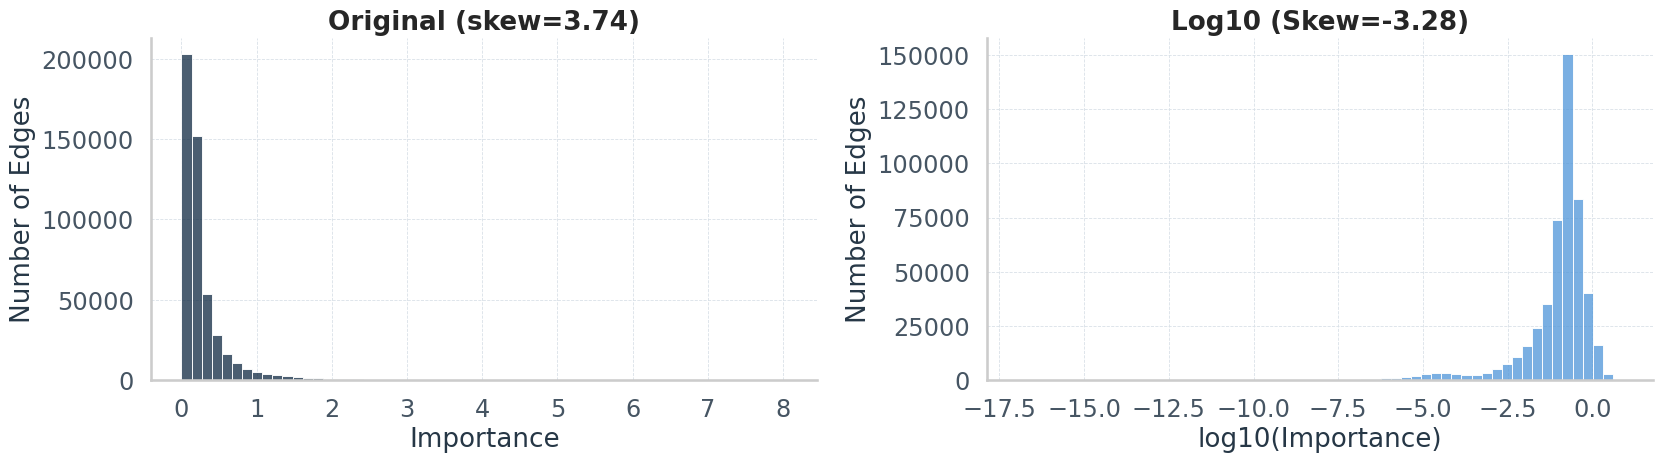

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# original values
sns.histplot(importance, bins=60, ax=axes[0], color=MAIN_COLOR)
axes[0].set_title(f"Original (skew={importance.skew():.2f})")
axes[0].set_xlabel("Importance")

# log10-transformed values
log_importance = np.log10(importance)
sns.histplot(log_importance, bins=60, ax=axes[1], color=ACCENT_COLOR)
axes[1].set_title(f"Log10 (Skew={log_importance.skew():.2f})")
axes[1].set_xlabel("log10(Importance)")

for ax in axes:
    ax.set_ylabel("Number of Edges")

plt.tight_layout()
plt.show()
plot.savefig(fig, REGION_DIR / "network_importance_distribution_summary.jpg")

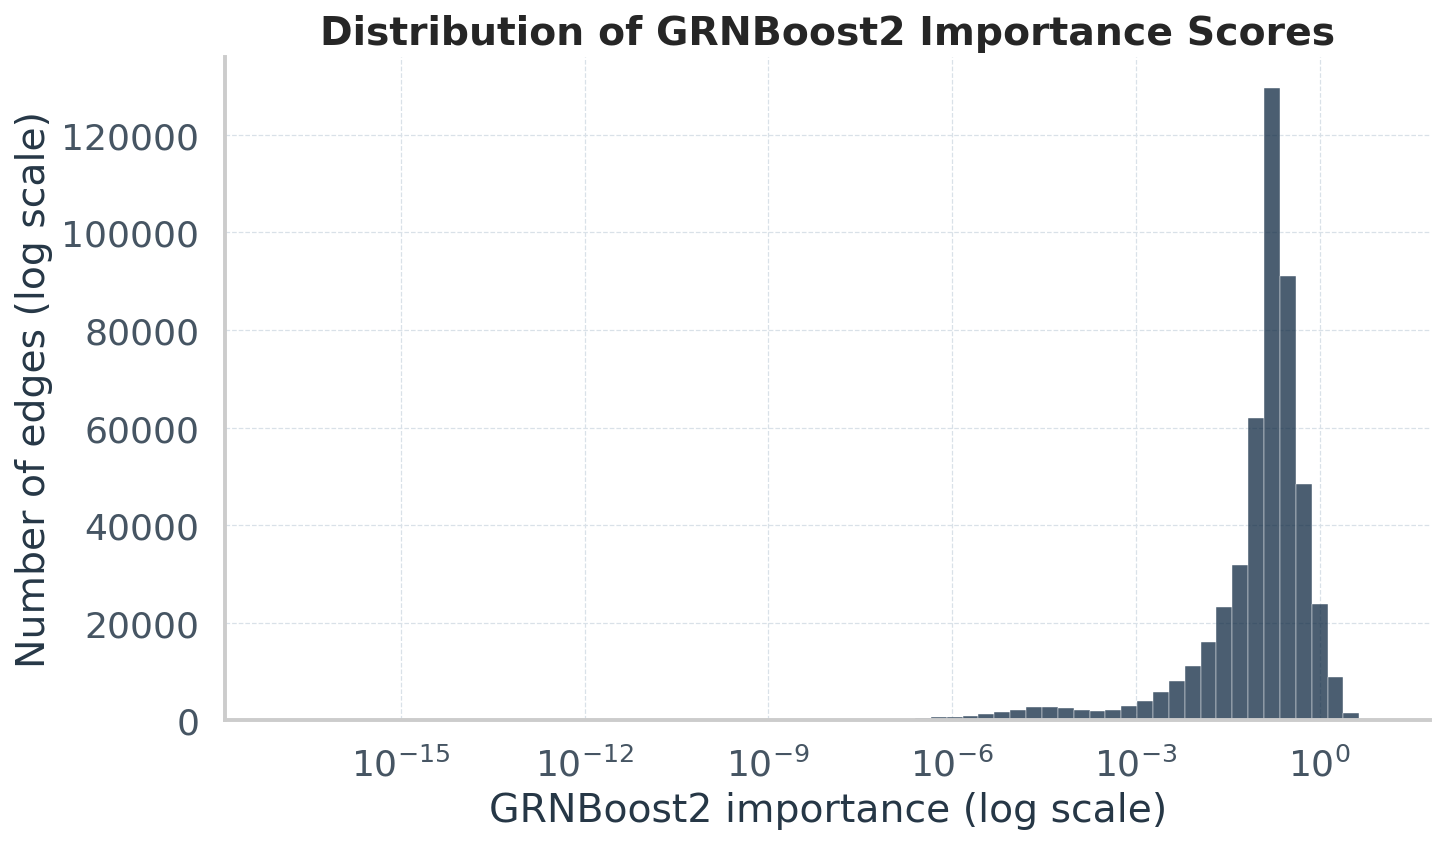

In [85]:
# log-scaled bins
bins = np.logspace(
    np.log10(importance.min()),
    np.log10(importance.max()),
    70
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

sns.histplot(
    importance,
    bins=bins,
    color=MAIN_COLOR,
    linewidth=0.2,
    ax=ax
)

ax.set_xscale("log")
ax.set_xlabel("GRNBoost2 importance (log scale)")
ax.set_ylabel("Number of edges (log scale)")
ax.set_title("Distribution of GRNBoost2 Importance Scores")

plt.tight_layout()
plt.show()
plot.savefig(fig, REGION_DIR / "network_importance_distribution_log.jpg")

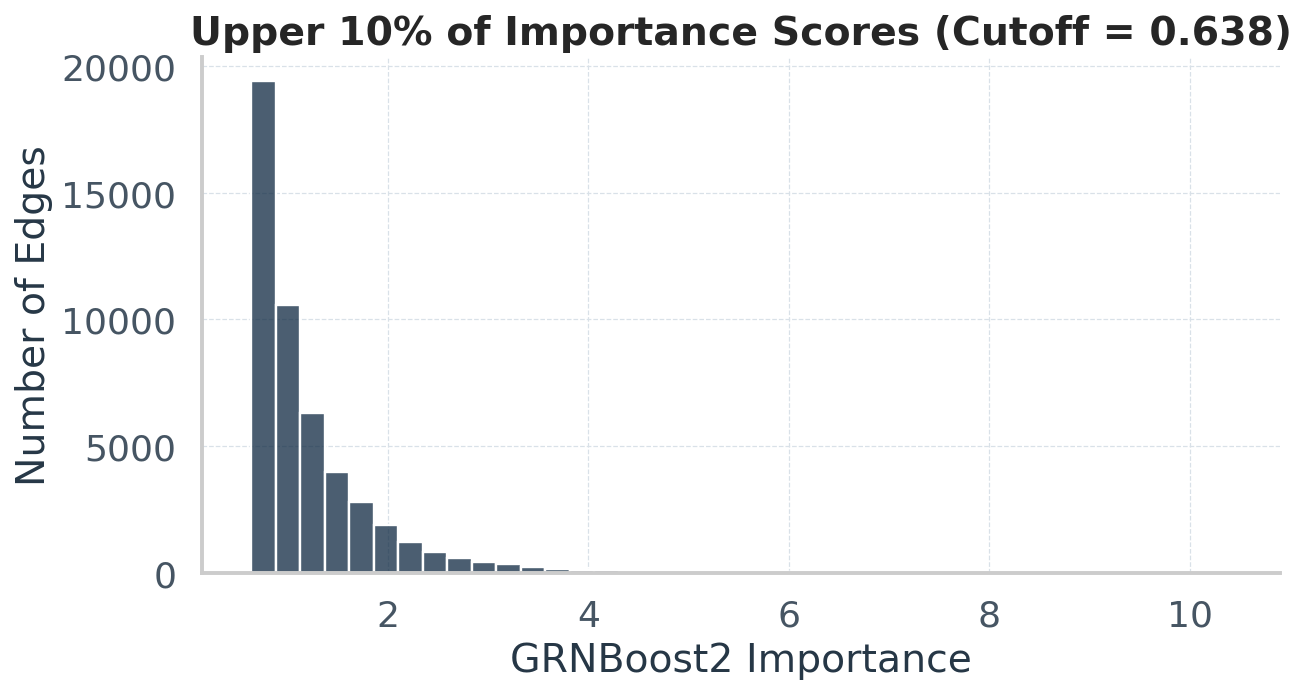

In [19]:
cutoff = importance.quantile(0.90)
upper = importance[importance >= cutoff]

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

sns.histplot(
    upper,
    bins=40,
    color=MAIN_COLOR,
    ax=ax
)
    
ax.set_xlabel("GRNBoost2 Importance")
ax.set_ylabel("Number of Edges")
ax.set_title(
    f"Upper 10% of Importance Scores (Cutoff = {cutoff:.3f})"
)
    
plt.tight_layout()
plt.show()
plot.savefig(fig, REGION_DIR / "network_importance_distribution_top10.jpg")

### Importance Score Filtering

In [23]:
MIN_IMPORTANCE = 0.1

In [24]:
importance_threshold = network[network["importance"] >= MIN_IMPORTANCE]

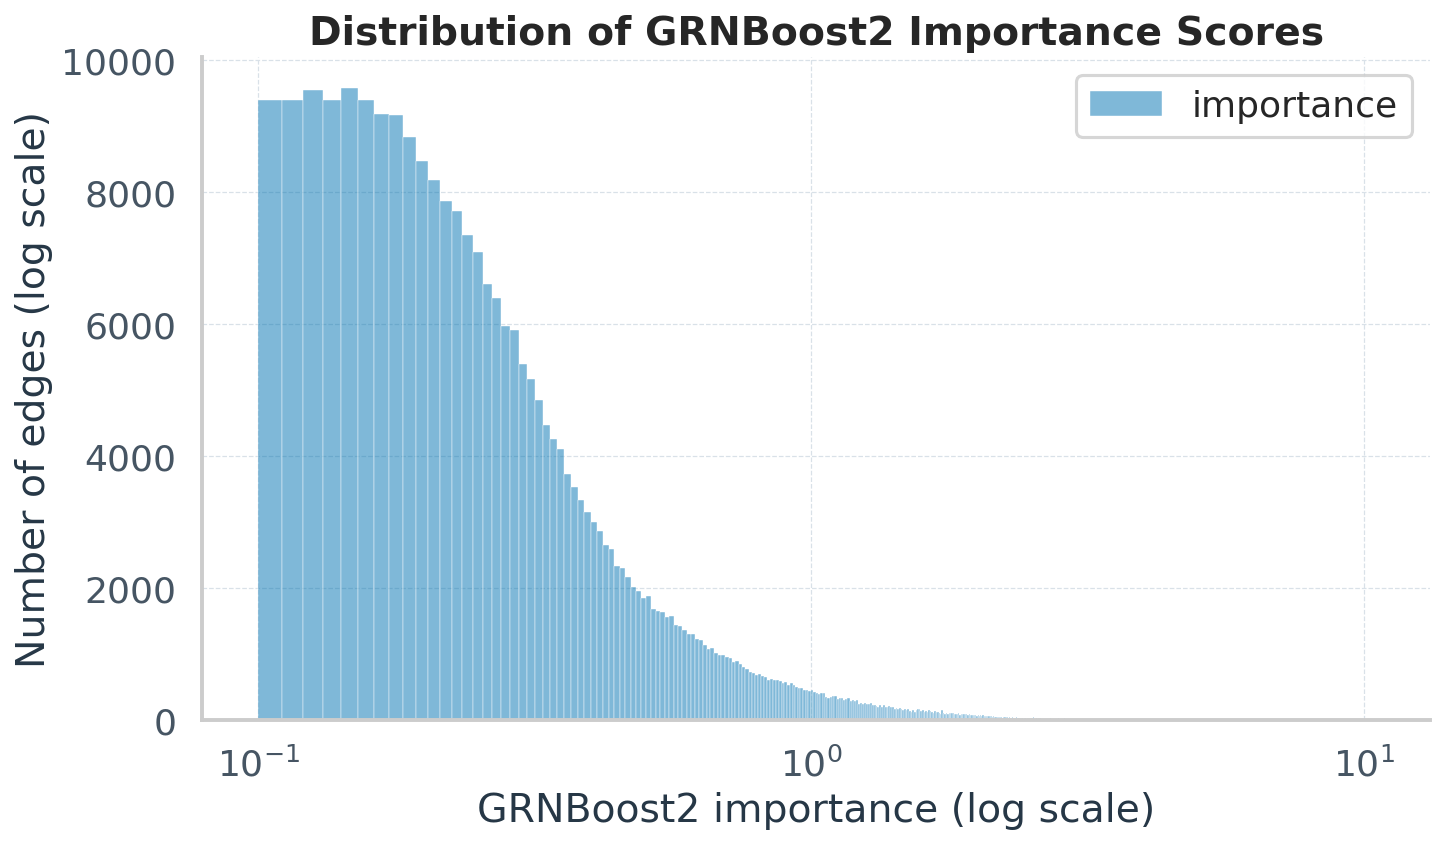

In [26]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

sns.histplot(
    importance_threshold,
    bins=1000,
    color=MAIN_COLOR,
    linewidth=0.2,
    ax=ax
)

ax.set_xscale("log")
ax.set_xlabel("GRNBoost2 importance (log scale)")
ax.set_ylabel("Number of edges (log scale)")
ax.set_title("Distribution of GRNBoost2 Importance Scores")

plt.tight_layout()
plt.show()
plot.savefig(fig, REGION_DIR / "network_importance_score_distribution_after_thresholding.jpg")

## Create Edge Table

In [27]:
edges = network.copy()

n_edges_before = len(edges)
edges = edges[edges["importance"] >= MIN_IMPORTANCE]

print("\nColumn Indices: ", edges.columns)

print("\nUnique TFs:", edges["TF"].nunique())
print("Unique targets:", edges["target"].nunique())
print("Unique genes:", len(set(edges["TF"]) | set(edges["target"])))
print("Number of edges before thresholding:", n_edges_before)
print("Number of edges after thrsholding:", len(edges))
print("Removed edges: ", n_edges_before - len(edges))


Column Indices:  Index(['TF', 'target', 'importance'], dtype='object')

Unique TFs: 422
Unique targets: 4719
Unique genes: 4719
Number of edges before thresholding: 491011
Number of edges after thrsholding: 289929
Removed edges:  201082


### Edge Filtering

In [28]:
q95 = edges["importance"].quantile(0.95)
edges_top5pct = edges[edges["importance"] >= q95].copy()

edges_top10_per_tf = (
    edges
    .sort_values("importance", ascending=False)
    .groupby("TF", group_keys=False)
    .head(10).copy())

edges_top25_per_tf = (
    edges
    .sort_values("importance", ascending=False)
    .groupby("TF", group_keys=False)
    .head(25).copy()
)

print("Full Network:", len(edges))
print("Top 5% globally:", len(edges_top5pct))
print("Top 10 per TF:", len(edges_top10_per_tf))
print("Top 25 per TF:", len(edges_top25_per_tf))

Full Network: 289929
Top 5% globally: 14497
Top 10 per TF: 4220
Top 25 per TF: 10550


## Adjacency Table 

In [29]:
G = nx.from_pandas_edgelist(
    edges,
    source="TF",
    target="target",
    edge_attr="importance",
    create_using=nx.DiGraph()
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Density:", nx.density(G))

Nodes: 4719
Edges: 289929
Density: 0.013022181487247578


### Standard Topology Metrics

In [30]:
tf_set = set(tf_names_present)
all_nodes = set(G.nodes())

tf_nodes = all_nodes & tf_set
target_nodes = {
    node for node in G.nodes()
    if G.in_degree(node) > 0
}

In [31]:
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

weighted_out_degree = dict(
    G.out_degree(weight="importance")
)

weighted_in_degree = dict(
    G.in_degree(weight="importance")
)

pagerank = nx.pagerank(G, weight="importance")

In [32]:
node_metrics = pd.DataFrame({
    "gene": list(G.nodes()),
    "in_degree": [in_degree[n] for n in G.nodes()],
    "out_degree": [out_degree[n] for n in G.nodes()],
    "weighted_in_degree": [
        weighted_in_degree[n] for n in G.nodes()
    ],
    "weighted_out_degree": [
        weighted_out_degree[n] for n in G.nodes()
    ],
    "pagerank": [pagerank[n] for n in G.nodes()],
})

node_metrics["is_TF"] = node_metrics["gene"].isin(tf_nodes)
node_metrics["is_target"] = node_metrics["gene"].isin(target_nodes)

tf_ranking = (
    node_metrics[node_metrics["is_TF"]]
    .sort_values("weighted_out_degree", ascending=False)
)

display(tf_ranking.head(10))

,gene,in_degree,out_degree,weighted_in_degree,weighted_out_degree,pagerank,is_TF,is_target
187,EZR,48,1713,24.687264,1170.894027,0.000207,True,True
0,XBP1,42,1634,23.213277,1013.858747,0.000206,True,True
468,YBX1,52,1746,22.557200,949.230593,0.000209,True,True
251,RPL35,63,1506,24.094360,898.740707,0.000208,True,True
174,TCF4,41,1396,23.467135,820.133601,0.000206,True,True
316,RPL6,66,1620,23.410817,810.179272,0.000207,True,True
46,IRF8,65,1546,24.663133,782.653945,0.000206,True,True
273,KLF6,65,1605,26.099355,774.071649,0.000210,True,True
39,MAFB,42,756,22.720922,773.597293,0.000207,True,True
215,REL,69,1442,26.647772,763.923992,0.000211,True,True


In [34]:
node_metrics.to_csv(
    REGION_DIR / "grn_node_metrics.csv",
    sep="\t",
    index=False
)

### Top-Ranked Edges

In [35]:
top_edges = network.nlargest(
    100, "importance"
).copy()

top_tf_summary = (
    top_edges.groupby("TF")
    .agg(
        edges_in_top100=("target", "nunique"),
        max_importance=("importance", "max"),
        mean_importance=("importance", "mean")
    )
    .sort_values("max_importance", ascending=False)
)

display(top_tf_summary.head(10))

,edges_in_top100,max_importance,mean_importance
TF,,,
XBP1,5,10.412514,6.226912
UQCRB,5,10.307667,6.971402
LMO2,2,9.234221,8.253218
TPI1,1,8.293881,8.293881
MAX,1,7.535574,7.535574
PDLIM5,7,7.091612,5.438762
SPI1,7,7.040111,5.720138
GRHPR,2,6.863028,6.850824
UBTF,2,6.588149,5.808646


In [36]:
top_tf_summary.to_csv(
    REGION_DIR / "top_ranked_edges.csv",
    sep="\t",
    index=False
)

### Highly Regulated Genes

In [37]:
top_regulated_genes = (
    node_metrics
    .sort_values("in_degree", ascending=False)
    .head(10)
)

display(top_regulated_genes[["gene", "in_degree", "weighted_in_degree"]])

,gene,in_degree,weighted_in_degree
1381,PEA15,115,48.799281
3639,EIF4H,112,39.636261
4370,C1orf43,108,33.735546
4473,RSL24D1,106,37.211666
4067,RPS6KA4,104,36.258260
660,FNBP4,104,46.041878
1524,EPB41L4A-AS1,103,36.528226
1801,PNP,101,38.389402
3788,PLEKHB2,99,39.865284
827,ASCC3,97,42.786340


In [38]:
top_regulated_genes.to_csv(
    REGION_DIR / "top_regulated_genes.csv",
    sep="\t",
    index=False
)

### Convergent Targets

In [39]:
top_tfs = tf_ranking.head(10)["gene"].tolist()

tf_target_matrix = (
    edges[edges["TF"].isin(top_tfs)]
    .pivot_table(
        index="target",
        columns="TF",
        values="importance",
        aggfunc="max",
        fill_value=0
    )
)

tf_target_matrix["n_top_TFs"] = (
    tf_target_matrix[top_tfs] > 0
).sum(axis=1)

tf_target_matrix["total_importance"] = (
    tf_target_matrix[top_tfs].sum(axis=1)
)

convergent_targets = tf_target_matrix.sort_values(
    ["n_top_TFs", "total_importance"],
    ascending=[False, False]
)

display(convergent_targets.head(10))

TF,EZR,IRF8,KLF6,MAFB,REL,RPL35,RPL6,TCF4,XBP1,YBX1,n_top_TFs,total_importance
target,,,,,,,,,,,,
ANXA1,0.692408,0.363782,0.372382,0.192760,0.564046,0.802923,0.310009,2.342806,0.220838,1.451320,10,7.313275
ERP29,0.570748,0.262756,0.000000,0.844799,0.312602,0.735118,0.305823,0.700414,3.219577,0.246042,9,7.197880
C15orf48,0.581408,0.996347,0.139384,1.407627,0.404663,0.756690,0.000000,1.061597,0.398306,0.668189,9,6.414211
DERL3,1.010710,0.778527,0.553405,0.388128,0.000000,0.697724,0.297202,0.479200,1.688743,0.424086,9,6.317726
NFKBIA,0.274367,0.167494,1.481515,0.911197,0.339022,0.356855,0.194683,0.940422,0.000000,0.352954,9,5.018509
MAP3K2,1.024964,0.918077,0.130744,0.153518,0.000000,0.679444,0.103110,0.820380,0.652027,0.161524,9,4.643788
CLEC10A,2.261065,5.917007,0.587618,0.189692,0.127706,0.104247,0.000000,0.438613,0.000000,0.997873,8,10.623820
COTL1,1.419545,1.725915,0.240332,0.193164,0.000000,0.000000,0.155141,1.169643,3.109942,0.692818,8,8.706500
TNFRSF14,2.638872,3.032811,0.244609,0.000000,0.000000,0.143671,0.113470,0.374325,0.737774,0.970648,8,8.256179


In [40]:
convergent_targets.to_csv(
    REGION_DIR / "convergent_targets.csv",
    sep="\t",
    index=False
)

# PHASE 2 - Prune Modules for Targets (RcisTarget)
--- 

In [43]:
db_fnames = glob.glob(str(DATABASES_GLOB))
    
dbs = [RankingDatabase(
    fname=fname, name=os.path.splitext(os.path.basename(fname))[0]
    ) for fname in db_fnames
]

print(dbs)

[FeatherRankingDatabase(name="hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings")]


In [44]:
modules = list(modules_from_adjacencies(network, expression_data))

with open(MODULES_FNAME, 'wb') as f:
    pickle.dump(modules, f)


2026-10-18 18:32:57,048 - pyscenic.utils - INFO - Calculating Pearson correlations.

2026-10-18 18:32:57,147 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2026-10-18 18:33:01,673 - pyscenic.utils - INFO - Creating modules.
c:\Users\oonak\anaconda3\envs\pyscenic\lib\site-packages\pyscenic\utils.py:244: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of panda

In [45]:
print("Total modules:", len(modules))
print("Module type:", type(modules[0]) if modules else None)

Total modules: 2446
Module type: <class 'ctxcore.genesig.Regulon'>


In [46]:
module_summary = pd.DataFrame([
    {
        "TF": module.transcription_factor,
        "Module": module.name,
        "Number_of_genes": len(module.genes),
    }
    for module in modules
])

display(
    pd.DataFrame(
        module_summary["Number_of_genes"].describe(
            percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
        )
    )
)

,Number_of_genes
count,2446.000000
mean,186.480785
std,196.265052
min,20.000000
25%,51.000000
50%,103.000000
75%,234.000000
90%,494.500000
95%,640.250000
max,1122.000000


In [47]:
display(
    module_summary.sort_values(
        "Number_of_genes",
        ascending=False
    ).head()
)

,TF,Module,Number_of_genes
2395,XBP1,XBP1,1122
2111,EZR,EZR,1054
2163,ID2,ID2,1016
2195,LRRFIP1,LRRFIP1,1003
2189,KLF6,KLF6,1002


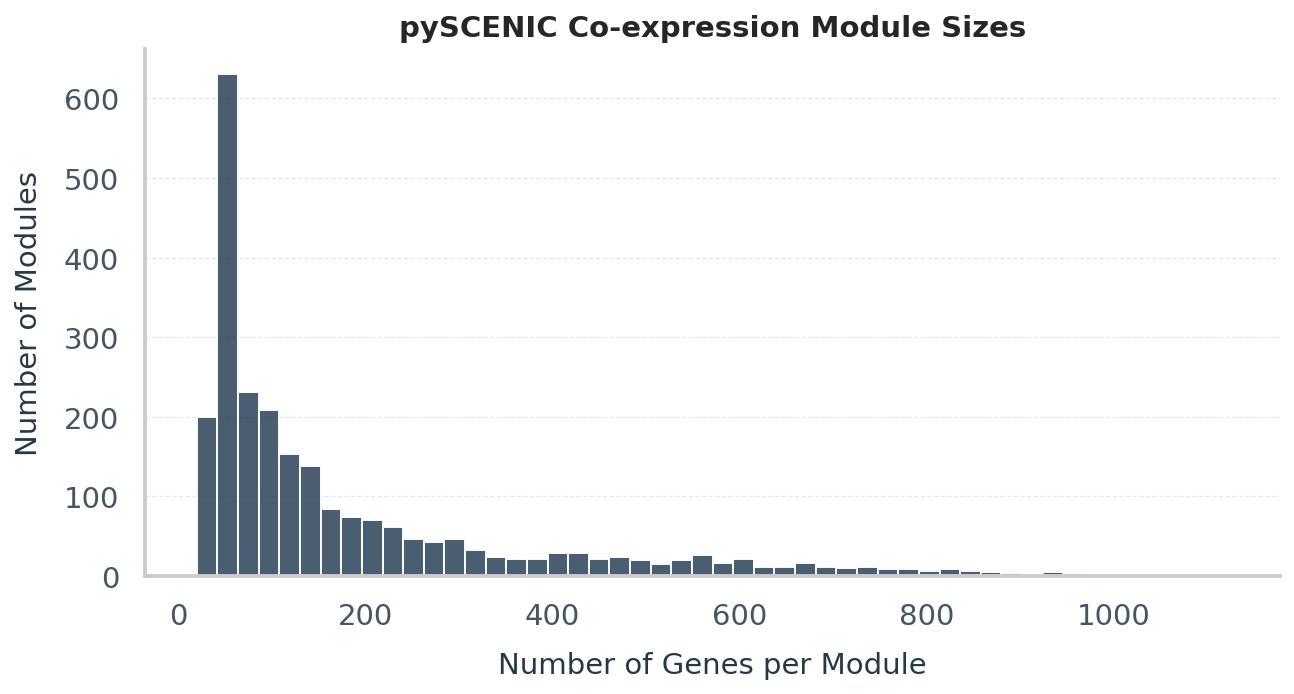

In [48]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

sns.histplot(
    data=module_summary,
    x="Number_of_genes",
    bins=50,
    color=MAIN_COLOR,
    ax=ax
)

ax.set_xlabel("Number of Genes per Module", fontsize=14, labelpad=10)
ax.set_ylabel("Number of Modules", fontsize=14, labelpad=10)
ax.tick_params(axis="both", labelsize=14)
ax.set_title("pySCENIC Co-expression Module Sizes", fontsize=14)
ax.grid(axis="y", alpha=0.7)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
plot.savefig(fig, REGION_DIR / "pyscenic_module_size.jpg")

In [49]:
modules_per_tf = (
    module_summary.groupby("TF")
    .agg(
        n_modules=("Module", "count"),
        max_module_size=("Number_of_genes", "max"),
        median_module_size=("Number_of_genes", "median")
    )
    .sort_values("max_module_size", ascending=False)
)

display(modules_per_tf.head())

,n_modules,max_module_size,median_module_size
TF,,,
XBP1,6,1122,343.5
EZR,6,1054,418.0
ID2,6,1016,158.0
LRRFIP1,6,1003,181.5
KLF6,6,1002,222.0


In [50]:
modules_per_tf.to_csv(
    REGION_DIR / "modules_per_tf.csv",
    sep="\t",
    index=False
)

#### Load Modules 

In [149]:
#with open(MODULES_FNAME, 'rb') as f:
    #modules = pickle.load(f)

## Motif Pruning

In [51]:
%%time

df = prune2df(dbs, modules, MOTIF_ANNOTATIONS_FNAME)
df.to_csv(MOTIFS_FNAME)

display(df.head())

Enrichment                                  \
                                 AUC       NES MotifSimilarityQvalue   
TF   MotifID                                                           
ATF4 metacluster_111.3      0.065510  3.326926          6.250900e-10   
ATF5 transfac_pro__M01861   0.066909  3.357065          4.689740e-06   
     metacluster_111.3      0.068170  3.480561          6.250900e-10   
BPTF tfdimers__MD00252      0.070344  3.078483          4.946340e-16   
ELF2 metacluster_183.4      0.090318  3.129519          3.299100e-09   

                                               \
                          OrthologousIdentity   
TF   MotifID                                    
ATF4 metacluster_111.3               1.000000   
ATF5 transfac_pro__M01861            1.000000   
     metacluster_111.3               1.000000   
BPTF tfdimers__MD00252               1.000000   
ELF2 metacluster_183.4               0.919056   

                                                                              \
                                                                  Annotation   
TF   MotifID                                                                   
ATF4 metacluster_111.3     motif similar to transfac_pro__M00981 ('V$CREB...   
ATF5 transfac_pro__M01861  gene is annotated for similar motif transfac_p...   
     metacluster_111.3     motif similar to transfac_pro__M00981 ('V$CREB...   
BPTF tfdimers__MD00252     gene is annotated for similar motif tfdimers__...   
ELF2 metacluster_183.4     motif similar to cisbp__M01494 ('ETV3L[gene ID...   

                                                                              \
                                                                     Context   
TF   MotifID                                                                   
ATF4 metacluster_111.3     (weight>75.0%, hg38_10kbp_up_10kbp_down_full_t...   
ATF5 transfac_pro__M01861  (weight>75.0%, hg38_10kbp_up_10kbp_down_full_t...   
     metacluster_111.3     (weight>75.0%, hg38_10kbp_up_10kbp_down_full_t...   
BPTF tfdimers__MD00252     (weight>75.0%, hg38_10kbp_up_10kbp_down_full_t...   
ELF2 metacluster_183.4     (weight>75.0%, hg38_10kbp_up_10kbp_down_full_t...   

                                                                              \
                                                                 TargetGenes   
TF   MotifID                                                                   
ATF4 metacluster_111.3     [(CYHR1, 0.5755966651647542), (PIGA, 0.3858065...   
ATF5 transfac_pro__M01861  [(IKZF1, 0.7813986348894207), (FBXW7, 0.437261...   
     metacluster_111.3     [(SNX9, 0.4965986523374681), (FBXW7, 0.4372610...   
BPTF tfdimers__MD00252     [(SLC5A3, 0.3572498229258087), (SCAF11, 0.3404...   
ELF2 metacluster_183.4     [(COMMD3, 0.532672460766188), (WASL, 0.5470786...   

                                     
                          RankAtMax  
TF   MotifID                         
ATF4 metacluster_111.3         1051  
ATF5 transfac_pro__M01861       439  
     metacluster_111.3         1206  
BPTF tfdimers__MD00252         1457  
ELF2 metacluster_183.4         1006

CPU times: total: 11.7 s
Wall time: 2min 27s



|Column |Meaning|
| --- | --- |
|AUC|Area under the Motif-Recovery Curve|
|NES|Normalized Enrichment Score|
|MotifSimilarityQvalue| Significance of Motif Similarity to an Annotated Motif|
|OrthologousIdentity| Identity Measure associated with Orthologous Motif Annotation|
|Annotation|Annotation Linking the Motif to a TF or Related Motif|
|Context|Regulatory Context Used in Enrichment|
|TargetGenes|Targets Retained for That Enriched Motif/Module|
|RankAtMax|Ranking Position at the mMximum of the Recovery Curve|


In [52]:
regulons = df2regulons(df)

with open(REGULONS_FNAME, 'wb') as f:
    pickle.dump(regulons, f)

Create regulons from a dataframe of enriched features.
Additional columns saved: []


In [53]:
regulons_raw = []

for reg in regulons:
    targets = reg.gene2weight

    regulons_raw.append({
        "TF": reg.transcription_factor,
        "Regulon": reg.name,
        "N_targets": len(targets),
        "Regulon_score": reg.score,
        "NES": reg.nes,
        "Annotation": reg.annotation,
        "Context": "; ".join(sorted(map(str, reg.context))),
        "Mean_target_weight": (
            sum(targets.values()) / len(targets)
            if targets else None
        )
    })

regulons_df = pd.DataFrame(regulons_raw)

regulons_df = regulons_df.sort_values(
    ["N_targets", "Regulon_score"],
    ascending=[False, False]
)

regulons_df.to_csv(
    REGION_DIR / "grn_regulons.csv", 
    index=False
)

display(regulons_df.head(10))
print("Total regulons:", len(regulons_df))

,TF,Regulon,N_targets,Regulon_score,NES,Annotation,Context,Mean_target_weight
19,ELK4,ELK4(+),274,5.045945,0.0,,activating; metacluster_191.3.png,0.389921
18,ELK3,ELK3(+),225,4.796373,0.0,,activating; taipale_tf_pairs__ETS2_RCCGGAAGTG_...,0.535885
53,NR3C1,NR3C1(+),197,5.434989,0.0,,activating; metacluster_33.8.png,0.494745
78,XBP1,XBP1(+),182,3.087434,0.0,,activating; metacluster_111.3.png,0.957382
81,ZBTB7A,ZBTB7A(+),168,4.172903,0.0,,activating; taipale_tf_pairs__ETS2_RCCGGAAGTG_...,0.508326
2,ATF4,ATF4(+),168,3.628466,0.0,,activating; metacluster_111.3.png,0.401578
44,MAFF,MAFF(+),154,4.061308,0.0,,activating; metacluster_22.25.png,1.254615
41,KLF4,KLF4(+),143,3.509296,0.0,,activating; metacluster_133.2.png,0.484492
42,KLF9,KLF9(+),131,3.686174,0.0,,activating; metacluster_131.7.png,0.579427
83,ZFX,ZFX(+),127,4.491531,0.0,,activating; metacluster_7.13.png,0.388295


Total regulons: 88


### Export Regulons to Cytoscape Edge Table

In [54]:
edges = []

for reg in regulons:
    tf = reg.transcription_factor

    for target, weight in reg.gene2weight.items():
        edges.append({
            "TF": tf,
            "target": target,
            "weight": weight,
            "regulon": reg.name,
            "regulon_score": reg.score,
            "context": "; ".join(sorted(map(str, reg.context)))
        })

edges = pd.DataFrame(edges)

edges = (
    edges.sort_values("weight", ascending=False)
         .drop_duplicates(["TF", "target"])
)

edges.to_csv(
    REGION_DIR / "cytoscape_edges_regulon.csv",
    index=False
)

print("TF-target edges:", len(edges))
print("Unique TFs:", edges["TF"].nunique())
print("Unique target genes:", edges["target"].nunique())

TF-target edges: 4923
Unique TFs: 88
Unique target genes: 2264


In [55]:
G = nx.from_pandas_edgelist(
    edges,
    source="TF",
    target="target",
    edge_attr="weight",
    create_using=nx.DiGraph()
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Density:", nx.density(G))

Nodes: 2286
Edges: 4923
Density: 0.0009424697186374679


In [56]:
tf_set = set(tf_names_present)
all_nodes = set(G.nodes())

tf_nodes = all_nodes & tf_set
target_nodes = {
    node for node in G.nodes()
    if G.in_degree(node) > 0
}

in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

weighted_in_degree = dict(G.in_degree(weight="weight"))
weighted_out_degree = dict(G.out_degree(weight="weight"))

in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

pagerank = nx.pagerank(G, weight="weight")

In [57]:
node_metrics = pd.DataFrame({
    "gene": list(G.nodes()),
    "in_degree": [in_degree[n] for n in G.nodes()],
    "out_degree": [out_degree[n] for n in G.nodes()],
    "weighted_in_degree": [
        weighted_in_degree[n] for n in G.nodes()
    ],
    "weighted_out_degree": [
        weighted_out_degree[n] for n in G.nodes()
    ],
    "pagerank": [pagerank[n] for n in G.nodes()],
})

node_metrics["is_TF"] = node_metrics["gene"].isin(tf_nodes)
node_metrics["is_target"] = node_metrics["gene"].isin(target_nodes)

tf_ranking = (
    node_metrics[node_metrics["is_TF"]]
    .sort_values("weighted_out_degree", ascending=False)
)

display(tf_ranking.head(10))

,gene,in_degree,out_degree,weighted_in_degree,weighted_out_degree,pagerank,is_TF,is_target
17,MAFF,1,154,1.451236,193.210708,0.000437,True,True
11,XBP1,1,182,0.068004,174.243571,0.000423,True,True
4,MAFB,1,39,0.550128,147.380800,0.000426,True,True
276,ELK3,4,225,4.060334,120.574175,0.000454,True,True
74,IRF7,0,106,0.000000,111.903563,0.000423,True,False
287,ELK4,4,274,4.233060,106.838481,0.000464,True,True
13,POU2F2,3,57,2.559658,97.576736,0.000438,True,True
303,NR3C1,4,197,1.862587,97.464712,0.000432,True,True
55,ZNF148,3,119,1.994002,94.433909,0.000433,True,True
15,ZBTB7A,1,168,1.000000,85.398769,0.000427,True,True


In [58]:
node_metrics.to_csv(
    REGION_DIR / "cytoscape_nodes_regulon.csv",
    sep="\t",
    index=False
)

#### Load Regulons

In [59]:
#with open(REGULONS_FNAME, 'rb') as f:
    #regulons = pickle.load(f)

# PHASE 3 - Cellular Regulon Enrichment Matrix (AUCell)
---

In [60]:
%%time

auc_mtx = aucell(expression_data, regulons, num_workers=4)

print("AUCell matrix shape:", auc_mtx.shape)
display(auc_mtx.head())

AUCell matrix shape: (36, 88)


Regulon,AHR(+),ARID3A(+),ATF4(+),ATF5(+),ATF6(+),BCL11A(+),BCLAF1(+),BPTF(+),CEBPA(+),CEBPB(+),...,XBP1(+),YY1(+),ZBTB1(+),ZBTB7A(+),ZFP90(+),ZFX(+),ZNF148(+),ZNF217(+),ZNF267(+),ZNF281(+)
Cell,,,,,,,,,,,,,,,,,,,,,
CCTTTGGTCATTGCCC-L2,0.000000,0.0,0.008457,0.003385,0.0,0.0,0.004349,0.012836,0.0,0.000000,...,0.077795,0.001665,0.0,0.003302,0.0,0.000342,0.0,0.0,0.002630,0.000000
GAGGCAATCCAGGACC-L2,0.000000,0.0,0.002981,0.002177,0.0,0.0,0.000000,0.000000,0.0,0.000000,...,0.053670,0.002548,0.0,0.013426,0.0,0.000806,0.0,0.0,0.003673,0.000000
CTCCATGAGCACCAGA-L2,0.020422,0.0,0.005205,0.007085,0.0,0.0,0.007707,0.014232,0.0,0.154668,...,0.006540,0.003056,0.0,0.009127,0.0,0.000000,0.0,0.0,0.004334,0.021865
AATCGACGTAGCCCTG-L2,0.000000,0.0,0.005788,0.002301,0.0,0.0,0.004252,0.000000,0.0,0.000000,...,0.048707,0.002925,0.0,0.011736,0.0,0.001770,0.0,0.0,0.006460,0.000000
ATGCATGAGCAAGCCA-L2,0.000000,0.0,0.010704,0.003843,0.0,0.0,0.003471,0.000000,0.0,0.000000,...,0.062897,0.001101,0.0,0.012445,0.0,0.001745,0.0,0.0,0.001919,0.000000


CPU times: total: 188 ms
Wall time: 13.7 s


In [61]:
auc_mtx.to_csv(AUCELL_FNAME)

In [62]:
auc_summary = pd.DataFrame({
    "mean_AUC": auc_mtx.mean(axis=0),
    "median_AUC": auc_mtx.median(axis=0),
    "sd_AUC": auc_mtx.std(axis=0),
    "variance_AUC": auc_mtx.var(axis=0)
})

auc_summary.index = (
    auc_summary.index
    .astype(str)
    .str.replace(r"\(\+\)$", "", regex=True)
)

auc_summary = auc_summary.sort_values(
    "variance_AUC", ascending=False
)

auc_summary.to_csv(
    REGION_DIR / "grn_auc.csv"
)

display(auc_summary.head(10))

,mean_AUC,median_AUC,sd_AUC,variance_AUC
Regulon,,,,
CEBPB,0.037856,0.000000,0.068532,0.004697
IRF7,0.080043,0.097067,0.051958,0.002700
JUN,0.029634,0.011949,0.037962,0.001441
JUND,0.108854,0.114846,0.035503,0.001260
ETV5,0.007820,0.001824,0.032193,0.001036
MITF,0.008654,0.000000,0.031051,0.000964
XBP1,0.045456,0.055057,0.030757,0.000946
MXD1,0.006476,0.000000,0.021890,0.000479
MAFB,0.010374,0.000000,0.021581,0.000466


# Regulatory Subnetworks for Cytoscape
---

In [63]:
TF_MODULES = {
    "hypoxia_stress": [
        "HIF1A", "EPAS1", "NFE2L2", "ATF4", "XBP1", "DDIT3"
    ],
    "EMT_plasticity": [
        "TWIST1", "SNAI1", "SNAI2", "ZEB1", "ZEB2",
        "FOXC2", "GRHL2", "OVOL1", "OVOL2",
        "PRRX1", "SIX1", "KLF8", "LEF1", "TCF7L2"
    ],
    "AP1_inflammation": [
        "JUN", "JUNB", "JUND", "FOS", "FOSB",
        "FOSL1", "FOSL2", "RELA", "NFKB1", "STAT3",
        "CEBPB", "IRF1", "IRF2"
    ],
    "migration_invasion": [
        "FOXC2", "TEAD1", "TEAD4", "YAP1", "WWTR1",
        "SMAD2", "SMAD3", "SMAD4", "RUNX1", "RUNX2",
        "PRRX1", "SIX1", "KLF8"
    ],
    "proliferation_outgrowth": [
        "E2F1", "E2F2", "E2F3", "MYC", "MYCN",
        "FOXM1", "TP53", "RB1", "SP1", "KLF5"
    ],
    "stemness_plasticity": [
        "SOX4", "SOX9", "ID1", "ID2", "ID3",
        "KLF4", "STAT3", "MYC", "SOX2", "NOTCH1", "RBPJ"
    ],
    "dormancy_relapse": [
        "NR2F1", "BHLHE41", "TP53", "FOXO3", "ATF4",
        "SMAD2", "SMAD3", "SOX9", "KLF4", "HBP1", "CDKN1A"
    ],
    "breast_lineage": [
        "ESR1", "PGR", "GATA3", "FOXA1", "FOXC1", "KLF5",
        "AR", "SOX10", "TRPS1"
    ],
    "oxidative_stress": [
        "NFE2L2", "JUNB", "FOSB", "ATF4", "XBP1", "DDIT3", "FOXO3"
    ],
    "metastatic_colonization": [
        "SP1", "KLF5", "CEBPB", "RUNX2", "RUNX1",
        "STAT3", "RELA", "MYC", "E2F1", "FOXM1"
    ],
    "immune_evasion": [
        "RELA", "NFKB1", "STAT3", "STAT1",
        "IRF1", "IRF2", "CEBPB", "JUNB", "HIF1A"
    ],
    "bone_tropism": [
        "RUNX2", "RUNX1", "TWIST1", "SNAI2", "ZEB1",
        "FOXC2", "SMAD2", "SMAD3", "STAT3"
    ]
}

In [67]:
subnetwork_tables = {}

for module_name, selected_tfs in TF_MODULES.items():

    # Select edges originating from TFs in this module
    focused_edges = edges[
        edges["TF"].isin(selected_tfs)
    ].copy()

    # Save the table in memory
    subnetwork_tables[module_name] = focused_edges

    # Export to CSV
    output_file = (
        SUBNETWORK_FOLDER / f"grn_subnetwork_{module_name}.csv"
    )

    focused_edges.to_csv(output_file, index=False)

    # Report summary
    n_tfs_found = focused_edges["TF"].nunique()
    n_targets = focused_edges["target"].nunique()

    print(
        f"{module_name}: "
        f"{len(focused_edges)} edges, "
        f"{n_tfs_found}/{len(set(selected_tfs))} TFs represented, "
        f"{n_targets} unique targets"
    )

print(f"\nSaved subnetworks to: {SUBNETWORK_FOLDER}")

hypoxia_stress: 391 edges, 3/6 TFs represented, 365 unique targets
EMT_plasticity: 22 edges, 1/14 TFs represented, 22 unique targets
AP1_inflammation: 271 edges, 8/13 TFs represented, 261 unique targets
migration_invasion: 0 edges, 0/13 TFs represented, 0 unique targets
proliferation_outgrowth: 0 edges, 0/10 TFs represented, 0 unique targets
stemness_plasticity: 143 edges, 1/11 TFs represented, 143 unique targets
dormancy_relapse: 317 edges, 3/11 TFs represented, 294 unique targets
breast_lineage: 0 edges, 0/9 TFs represented, 0 unique targets
oxidative_stress: 430 edges, 4/7 TFs represented, 388 unique targets
metastatic_colonization: 24 edges, 2/10 TFs represented, 24 unique targets
immune_evasion: 98 edges, 6/9 TFs represented, 93 unique targets
bone_tropism: 0 edges, 0/9 TFs represented, 0 unique targets

Saved subnetworks to: C:\Users\oonak\Desktop\MSB1015\results\runs\20261018\grn-inference\Activated T cells\L\subnetwork
